**Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**05 | Cross-Person Evaluation and Robustness**

**Objective:** Compare the four fixed classical and neural procedures using matched outer-LOPO predictions from the same indexed MPIIGaze cohort.

**Data:** 7,500 left-eye samples from 15 participants, with one held-out participant per fold.

**Current evidence:** Notebook 03 has produced the complete classical outer-Test prediction table (15,000 rows). Notebook 04 has also produced its complete neural outer-Test prediction table (15,000 rows). Both tables are available for matched evaluation. The four predefined procedures remain fixed.

**Scope:** Reconcile sample and role identities, recompute 3D angular errors, summarise participant-level performance, describe uncertainty and image-quality strata. The primary outcome is the equally weighted mean of participant mean angular errors. This is an internal evaluation on a study-defined subset, not an external or official benchmark. No models are fitted here.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / "Eye-Tracking-Neurocognitive-Intelligence"
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# --------------------------- 1. Study Environment ----------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("vision_based_gaze_estimation")

# -------------------- 2. Scientific Analysis and Plotting --------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ----------------------- 3. Study Evaluation Utilities -----------------------
from gaze_evaluation import reconcile_outer_predictions, summarise_outer_evaluation
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

out_dir = root / "vision_based_gaze_estimation" / "output"
MODELS = ("mean_direction", "hog_ridge", "small_cnn", "resnet18")
LABELS = dict(zip(MODELS, ("Mean direction", "HOG + Ridge", "Small CNN", "ResNet-18")))
plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
           label_size=11.5, label_weight="normal", tick_size=10,
           legend_size=10, figure_dpi=100, figure_size=(10, 5))

Local changes kept; continuing with the current checkout. Conflicting Git update deferred.


**02. Prediction Alignment and Integrity**

Require current complete prediction and configuration tables from both modelling stages. Match every model to every indexed sample exactly once, verify its outer Test person and fold, compare the saved target vectors with the index and recompute angular error from unit directions. Development-only predictions are not valid inputs.

In [3]:
# =================== 02. Reconcile Full Outer Predictions ====================

# ----------------------- 1. Load Current Stage Tables ------------------------
required = ["02_sample_index.csv", "02_fold_assignments.csv",
            "03_baseline_outer_predictions.csv", "04_neural_outer_predictions.csv",
            "03_run_configuration.csv", "04_run_configuration.csv",
            "04_inner_validation_metrics.csv"]
missing = [name for name in required if not (out_dir / name).is_file()]
if missing:
    raise FileNotFoundError("Complete Notebooks 03 and 04 first: " + ", ".join(missing))
index = pd.read_csv(out_dir / required[0], dtype={"sample_id": str, "participant_id": str})
folds = pd.read_csv(out_dir / required[1], dtype=str)
prediction_ids = {"sample_id": str, "participant_id": str, "fold_id": str, "model": str}
classical = pd.read_csv(out_dir / required[2], dtype=prediction_ids)
neural = pd.read_csv(out_dir / required[3], dtype=prediction_ids)
classical_config = pd.read_csv(out_dir / required[4])
neural_config = pd.read_csv(out_dir / required[5])
neural_metrics = pd.read_csv(out_dir / required[6])

# --------------------- 2. Check Full Run Configurations ----------------------
for config, models, mode, selection_col in (
    (classical_config, MODELS[:2], "full_outer_lopo", "test_used_for_selection"),
    (neural_config, MODELS[2:], "final_outer_lopo", "test_used_for_model_selection"),
):
    expected = {(fold, model) for fold in folds.fold_id.unique() for model in models}
    actual = set(zip(config.fold_id, config.model))
    if (actual != expected or len(config) != len(expected)
            or not config.run_mode.eq(mode).all()
            or selection_col not in config.columns
            or not config[selection_col].astype(str).str.lower().eq("false").all()):
        raise ValueError("Incomplete final configuration or invalid Test selection")
if (not classical_config.outer_fold_count.eq(folds.fold_id.nunique()).all()
        or not neural_config.evaluated_folds.eq(folds.fold_id.nunique()).all()
        or not neural_config.all_outer_folds.eq(folds.fold_id.nunique()).all()):
    raise ValueError("Configuration fold counts do not match the source design")
if (set(classical.model) != set(MODELS[:2]) or set(neural.model) != set(MODELS[2:])):
    raise ValueError("Unexpected model family in stage predictions")

# -------------------- 3. Recompute Matched Angular Errors --------------------
observed, participant_metrics = reconcile_outer_predictions(
    pd.concat([classical, neural], ignore_index=True), index, folds, MODELS)
print("Matched predictions:", len(observed))
print("Independent participants:", index.participant_id.nunique())
print("Full outer folds:", folds.fold_id.nunique())

Matched predictions: 30000
Independent participants: 15
Full outer folds: 15


**03. Overall Model Performance**

The primary metric gives equal weight to each participant's mean angular error. Pooled image-level statistics describe the same predictions but are not independent-person estimates. Report all four predefined procedures without using Test to select a new winner.

In [4]:
# ==================== 03. Summarise Overall Angular Error ====================

model_metrics, paired_differences = summarise_outer_evaluation(
    observed, participant_metrics, MODELS, seed=17, draws=5000)
display(model_metrics.round(4))

,model,n_people,n_samples,participant_macro_mean_deg,participant_mean_sd_deg,pooled_mean_deg,pooled_median_deg,pooled_sd_deg,pooled_rmse_deg,participant_bootstrap_ci_low_deg,participant_bootstrap_ci_high_deg
0,mean_direction,15,7500,9.1601,0.7654,9.1601,8.9879,4.0293,10.0070,8.8089,9.5587
1,hog_ridge,15,7500,7.5596,1.0673,7.5596,7.0152,4.1660,8.6314,7.0451,8.0824
2,small_cnn,15,7500,7.3048,1.1635,7.3048,6.8695,3.8331,8.2493,6.7381,7.8610
3,resnet18,15,7500,8.2304,0.8813,8.2304,7.7005,4.3851,9.3255,7.7978,8.6473


**04. Participant-Level Performance**

Compare the mean and median angular error for each held-out participant. The same participants and samples are evaluated by every model. The figure displays the variation across participants, not independent repeated trials.

,model,fold_id,participant_id,n_samples,mean_angular_error_deg,median_angular_error_deg
0,hog_ridge,outer_01,p00,500,6.4655,6.1409
1,hog_ridge,outer_02,p01,500,7.2636,6.9731
2,hog_ridge,outer_03,p02,500,7.2639,7.0408
3,hog_ridge,outer_04,p03,500,8.0951,7.6569
4,hog_ridge,outer_05,p04,500,5.9369,5.6103
5,hog_ridge,outer_06,p05,500,7.0055,6.4515
6,hog_ridge,outer_07,p06,500,8.2365,7.9407
7,hog_ridge,outer_08,p07,500,8.6321,7.7922
8,hog_ridge,outer_09,p08,500,8.7965,8.1163
9,hog_ridge,outer_10,p09,500,9.6914,9.6768


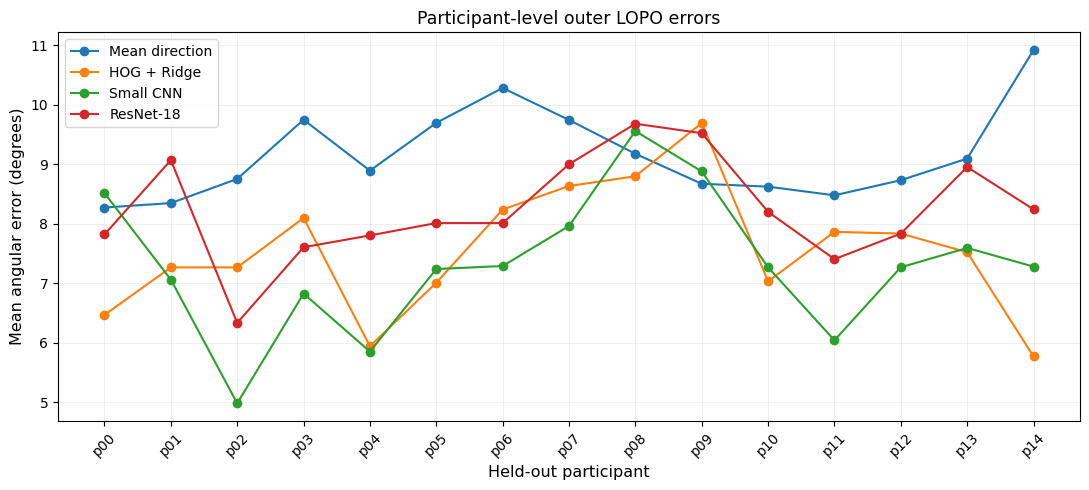

In [5]:
# ================== 04. Inspect Held-Out Participant Errors ==================

display(participant_metrics.round(4))
person_pivot = participant_metrics.pivot(index="participant_id", columns="model",
                                       values="mean_angular_error_deg")[list(MODELS)]
fig, ax = plt.subplots(figsize=(11, 5))
for model in MODELS:
    ax.plot(person_pivot.index, person_pivot[model], marker="o", label=LABELS[model])
ax.set(xlabel="Held-out participant", ylabel="Mean angular error (degrees)",
       title="Participant-level outer LOPO errors")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
save_figure(fig, out_dir / "05_participant_comparison.png")
plt.show()

**05. Error Distribution and Image-Quality Strata**

Inspect pooled error distributions and descriptive performance across low, middle and high image-intensity and pixel-contrast strata. The strata are defined from the indexed image statistics by cohort tertiles, not from prediction errors. Report the number of images and participants per group, and equal-weight participant means within each stratum. Pixel statistics are not calibrated illumination, head pose or clinical quality measures.

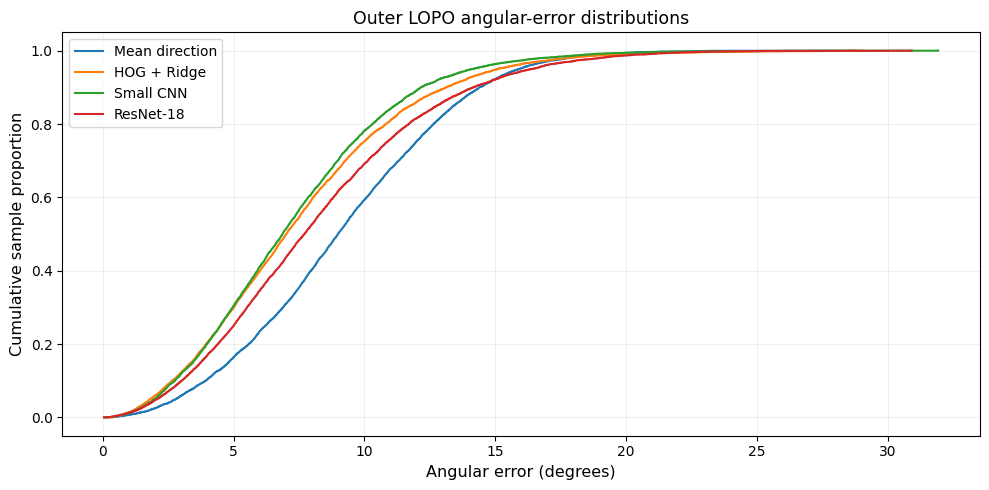

,feature,model,stratum,n_samples,n_people,participant_macro_mean_deg
0,mean_pixel_intensity,hog_ridge,"(83.86699999999999, 128.519]",2501,15,7.5364
1,mean_pixel_intensity,hog_ridge,"(128.519, 129.38]",2499,15,7.5038
2,mean_pixel_intensity,hog_ridge,"(129.38, 216.378]",2500,15,7.9032
3,mean_pixel_intensity,mean_direction,"(83.86699999999999, 128.519]",2501,15,9.3901
4,mean_pixel_intensity,mean_direction,"(128.519, 129.38]",2499,15,9.2712
5,mean_pixel_intensity,mean_direction,"(129.38, 216.378]",2500,15,9.1390
6,mean_pixel_intensity,resnet18,"(83.86699999999999, 128.519]",2501,15,8.3388
7,mean_pixel_intensity,resnet18,"(128.519, 129.38]",2499,15,8.2876
8,mean_pixel_intensity,resnet18,"(129.38, 216.378]",2500,15,8.7540
9,mean_pixel_intensity,small_cnn,"(83.86699999999999, 128.519]",2501,15,7.3023


In [6]:
# ================ 05. Describe Error Distribution and Strata =================

# ----------------------- 1. Pooled Error Distributions -----------------------
fig, ax = plt.subplots(figsize=(10, 5))
for model in MODELS:
    errors = np.sort(observed.loc[observed.model.eq(model), "angular_error_deg"])
    ax.step(errors, np.arange(1, len(errors) + 1) / len(errors),
            where="post", label=LABELS[model])
ax.set(xlabel="Angular error (degrees)", ylabel="Cumulative sample proportion",
       title="Outer LOPO angular-error distributions")
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
save_figure(fig, out_dir / "05_error_distribution.png")
plt.show()

# -------------------- 2. Descriptive Image-Quality Strata --------------------
strata = []
for feature in ("mean_pixel_intensity", "pixel_std"):
    source = index[["sample_id", feature]].copy()
    if not np.isfinite(source[feature]).all():
        raise ValueError(f"Non-finite image statistic: {feature}")
    source["stratum"] = pd.qcut(source[feature], q=3, duplicates="drop")
    if source.stratum.isna().any():
        raise ValueError(f"Cannot form image-quality strata: {feature}")
    grouped = observed.merge(source, on="sample_id", validate="many_to_one")
    per_group = (grouped.groupby(["model", "stratum", "participant_id"], observed=True)
                 .angular_error_deg.agg(n_samples="size", person_mean_deg="mean")
                 .reset_index())
    result = (per_group.groupby(["model", "stratum"], observed=True)
              .agg(n_samples=("n_samples", "sum"), n_people=("participant_id", "nunique"),
                   participant_macro_mean_deg=("person_mean_deg", "mean")).reset_index())
    result.insert(0, "feature", feature)
    result["stratum"] = result.stratum.astype(str)
    strata.append(result)
stratum_metrics = pd.concat(strata, ignore_index=True)
display(stratum_metrics.round(4))

**06. Participant-Level Uncertainty**

Use 5,000 paired participant-summary bootstrap resamples (seed 17). Report descriptive 95% percentile intervals for model means and pairwise differences, with negative differences indicating lower error for model A. Because LOPO training sets overlap and models are not refitted within bootstrap samples, these intervals describe conditional participant variation, not full algorithmic or population-level uncertainty. No significance tests or retrospective model selection are performed.

,model_a,model_b,n_people,mean_a_minus_b_deg,people_a_lower_error,people_equal_error,paired_bootstrap_ci_low_deg,paired_bootstrap_ci_high_deg
0,mean_direction,hog_ridge,15,1.6005,1,0,0.9620,2.3090
1,mean_direction,small_cnn,15,1.8553,3,0,1.1876,2.4912
2,mean_direction,resnet18,15,0.9297,3,0,0.3869,1.4793
3,hog_ridge,small_cnn,15,0.2549,6,0,-0.3064,0.7984
4,hog_ridge,resnet18,15,-0.6707,9,0,-1.1688,-0.1776
5,small_cnn,resnet18,15,-0.9256,14,0,-1.2452,-0.5942


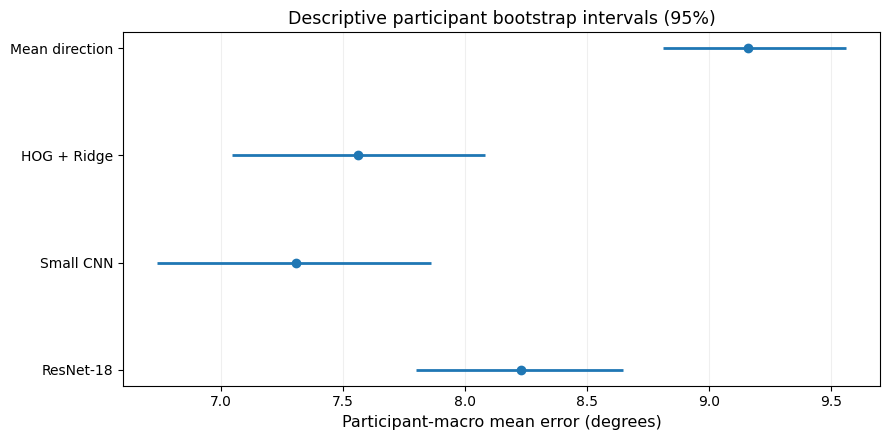

In [7]:
# ================ 06. Inspect Paired Participant Differences =================

display(paired_differences.round(4))
fig, ax = plt.subplots(figsize=(9, 4.5))
positions = np.arange(len(MODELS))
table = model_metrics.set_index("model").loc[list(MODELS)]
means = table.participant_macro_mean_deg.to_numpy()
ax.hlines(positions, table.participant_bootstrap_ci_low_deg,
          table.participant_bootstrap_ci_high_deg, linewidth=2)
ax.scatter(means, positions, zorder=3)
ax.set_yticks(positions, [LABELS[m] for m in MODELS])
ax.invert_yaxis()
ax.set(xlabel="Participant-macro mean error (degrees)",
       title="Descriptive participant bootstrap intervals (95%)")
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
save_figure(fig, out_dir / "05_participant_uncertainty.png")
plt.show()

**07. Model Complexity and Comparative Analysis**

Report HOG descriptor length and the recorded neural parameter counts. The parameter counts are not measured training time, inference latency or memory consumption. No such measurements are available in the current configuration tables.

In [8]:
# =================== 07. Compare Recorded Model Complexity ===================

complexity_rows = [
    {"model": "mean_direction", "hog_features": np.nan, "neural_parameters": np.nan},
    {"model": "hog_ridge", "hog_features": 360, "neural_parameters": np.nan},
]
for model in MODELS[2:]:
    part = neural_metrics.loc[neural_metrics.model.eq(model)]
    counts = part.parameters.unique()
    if (set(part.fold_id) != set(folds.fold_id) or part.fold_id.duplicated().any()
            or len(counts) != 1 or not np.isfinite(counts[0]) or counts[0] <= 0):
        raise ValueError(f"Inconsistent neural parameter metadata: {model}")
    complexity_rows.append({"model": model, "hog_features": np.nan,
                            "neural_parameters": int(counts[0])})
complexity = pd.DataFrame(complexity_rows)
display(complexity)

,model,hog_features,neural_parameters
0,mean_direction,NaN,NaN
1,hog_ridge,360.0,NaN
2,small_cnn,NaN,48387.0
3,resnet18,NaN,11171779.0


**08. Save Results and Scientific Interpretation**

Save the current model, participant, paired-difference, image-stratum and complexity tables together with the computed figures. All results refer to the fixed MPIIGaze subset and normalised target representation. Earlier development observations across the cohort limit claims of a wholly untouched evaluation population; the physical gaze-axis convention has not been independently confirmed. The analysis supports internal participant-disjoint comparisons, not external or clinical validation.

In [9]:
# ==================== 08. Save Final Comparative Evidence ====================

# ------------------------------ 1. Save Tables -------------------------------
tables = {
    "05_model_metrics.csv": model_metrics,
    "05_participant_metrics.csv": participant_metrics,
    "05_paired_differences.csv": paired_differences,
    "05_image_stratum_metrics.csv": stratum_metrics,
    "05_model_complexity.csv": complexity,
}
for name, table in tables.items():
    table.to_csv(out_dir / name, index=False)

# ------------------------ 2. Package Current Outputs -------------------------
download_outputs_from_colab("vision_based_gaze_estimation/output", "05")

------------------------------------------------------------------------
Notebook 05
Files packaged: 8
  + 05_error_distribution.png
  + 05_image_stratum_metrics.csv
  + 05_model_complexity.csv
  + 05_model_metrics.csv
  + 05_paired_differences.csv
  + 05_participant_comparison.png
  + 05_participant_metrics.csv
  + 05_participant_uncertainty.png
Download ZIP from Colab Contents: /content/vision_based_gaze_estimation_Notebook_05_Outputs.zip
